# Analyse de données financières : actions bancaires (2006–2016)

Projet d'analyse exploratoire des cours de bourse : on étudie 6 banques américaines pendant la **crise financière de 2007-2008** et jusqu'à début 2016.

**Banques étudiées :** Bank of America (BAC), Citigroup (C), Goldman Sachs (GS), JPMorgan Chase (JPM), Morgan Stanley (MS), Wells Fargo (WFC).

> **Version adaptée à Google Colab.** Le notebook d'origine utilisait `pandas_datareader` avec la source `'google'`, qui n'existe plus, ainsi que `.ix`, `distplot` et `cufflinks`, qui ne fonctionnent plus avec les versions récentes. Ici les données viennent de **Yahoo Finance (`yfinance`)** et les graphiques interactifs sont faits avec **Plotly**.

## 0. Installation et imports

In [1]:
!pip install -q -U yfinance plotly

In [2]:
import datetime
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px

sns.set_style('whitegrid')
%matplotlib inline

## 1. Récupération des données

1. On définit les dates de début et de fin.
2. On télécharge chaque banque dans un DataFrame séparé, nommé d'après son symbole boursier.
3. On les regroupe dans un seul DataFrame, `bank_stocks`.

In [3]:
start = datetime.datetime(2006, 1, 1)
end = datetime.datetime(2016, 1, 1)

# Liste des symboles, par ordre alphabétique
tickers = ['BAC', 'C', 'GS', 'JPM', 'MS', 'WFC']


def get_stock(ticker):
    """Télécharge les cours d'une action depuis Yahoo Finance."""
    df = yf.download(ticker, start=start, end=end, auto_adjust=False, progress=False)
    # Les versions récentes de yfinance renvoient des colonnes à 2 niveaux : on garde le 1er
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df.columns.name = None
    return df


BAC = get_stock('BAC')   # Bank of America
C = get_stock('C')       # Citigroup
GS = get_stock('GS')     # Goldman Sachs
JPM = get_stock('JPM')   # JPMorgan Chase
MS = get_stock('MS')     # Morgan Stanley
WFC = get_stock('WFC')   # Wells Fargo

print(BAC.shape)
BAC.head()

(2517, 6)


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2006-01-03,30.176394,47.080002,47.180000,46.150002,46.919998,16296700
2006-01-04,29.855909,46.580002,47.240002,46.450001,47.000000,17757900
2006-01-05,29.894365,46.639999,46.830002,46.320000,46.580002,14970700
2006-01-06,29.849489,46.570000,46.910000,46.349998,46.799999,12599800
2006-01-09,29.868725,46.599998,46.970001,46.360001,46.720001,15619400


On concatène les 6 DataFrames en un seul (`axis=1`), avec les symboles comme clés (`keys=tickers`).

In [4]:
bank_stocks = pd.concat([BAC, C, GS, JPM, MS, WFC], axis=1, keys=tickers)
bank_stocks.columns.names = ['Bank Ticker', 'Stock Info']
bank_stocks.head()

Bank Ticker        BAC                                                        \
Stock Info   Adj Close      Close       High        Low       Open    Volume   
Date                                                                           
2006-01-03   30.176394  47.080002  47.180000  46.150002  46.919998  16296700   
2006-01-04   29.855909  46.580002  47.240002  46.450001  47.000000  17757900   
2006-01-05   29.894365  46.639999  46.830002  46.320000  46.580002  14970700   
2006-01-06   29.849489  46.570000  46.910000  46.349998  46.799999  12599800   
2006-01-09   29.868725  46.599998  46.970001  46.360001  46.720001  15619400   

Bank Ticker           C                                      ...         MS  \
Stock Info    Adj Close       Close        High         Low  ...       High   
Date                                                         ...              
2006-01-03   311.018311  492.899994  493.799988  481.100006  ...  58.490002   
2006-01-04   305.276245  483.799988  491.000000  483.500000  ...  59.279999   
2006-01-05   306.790619  486.200012  487.799988  484.000000  ...  58.590000   
2006-01-06   306.790619  486.200012  489.000000  482.000000  ...  58.849998   
2006-01-09   305.339386  483.899994  487.399994  483.000000  ...  59.290001   

Bank Ticker                                       WFC                        \
Stock Info         Low       Open   Volume  Adj Close      Close       High   
Date                                                                          
2006-01-03   56.740002  57.169998  5377000  18.063210  31.900000  31.975000   
2006-01-04   58.349998  58.700001  7977800  17.853695  31.530001  31.820000   
2006-01-05   58.020000  58.549999  5778000  17.833878  31.495001  31.555000   
2006-01-06   58.049999  58.770000  6889800  17.938631  31.680000  31.775000   
2006-01-09   58.619999  58.630001  4144500  17.935814  31.674999  31.825001   

Bank Ticker                                  
Stock Info         Low       Open    Volume  
Date                                         
2006-01-03   31.195000  31.600000  11016400  
2006-01-04   31.365000  31.799999  10870000  
2006-01-05   31.309999  31.500000  10158000  
2006-01-06   31.385000  31.580000   8403800  
2006-01-09   31.555000  31.674999   5619600  

[5 rows x 36 columns]

## 2. Analyse exploratoire (EDA)

**Quel est le cours de clôture maximal de chaque banque sur la période ?**

In [5]:
close = bank_stocks.xs(key='Close', axis=1, level='Stock Info')
close.max()

,0
Bank Ticker,
BAC,54.900002
C,564.099976
GS,247.919998
JPM,70.080002
MS,89.300003
WFC,58.520000


**Rendements journaliers.** On calcule pour chaque banque :

$$r_t = \frac{p_t - p_{t-1}}{p_{t-1}} = \frac{p_t}{p_{t-1}} - 1$$

In [6]:
returns = pd.DataFrame()
for tick in tickers:
    returns[tick + ' Return'] = bank_stocks[tick]['Close'].pct_change()
returns.head()

,BAC Return,C Return,GS Return,JPM Return,MS Return,WFC Return
Date,,,,,,
2006-01-03,NaN,NaN,NaN,NaN,NaN,NaN
2006-01-04,-0.010620,-0.018462,-0.013812,-0.014183,0.000686,-0.011599
2006-01-05,0.001288,0.004961,-0.000393,0.003029,0.002742,-0.001110
2006-01-06,-0.001501,0.000000,0.014169,0.007046,0.001025,0.005874
2006-01-09,0.000644,-0.004731,0.012030,0.016242,0.010586,-0.000158


**Pairplot des rendements** : quelle action se démarque, et pourquoi ?

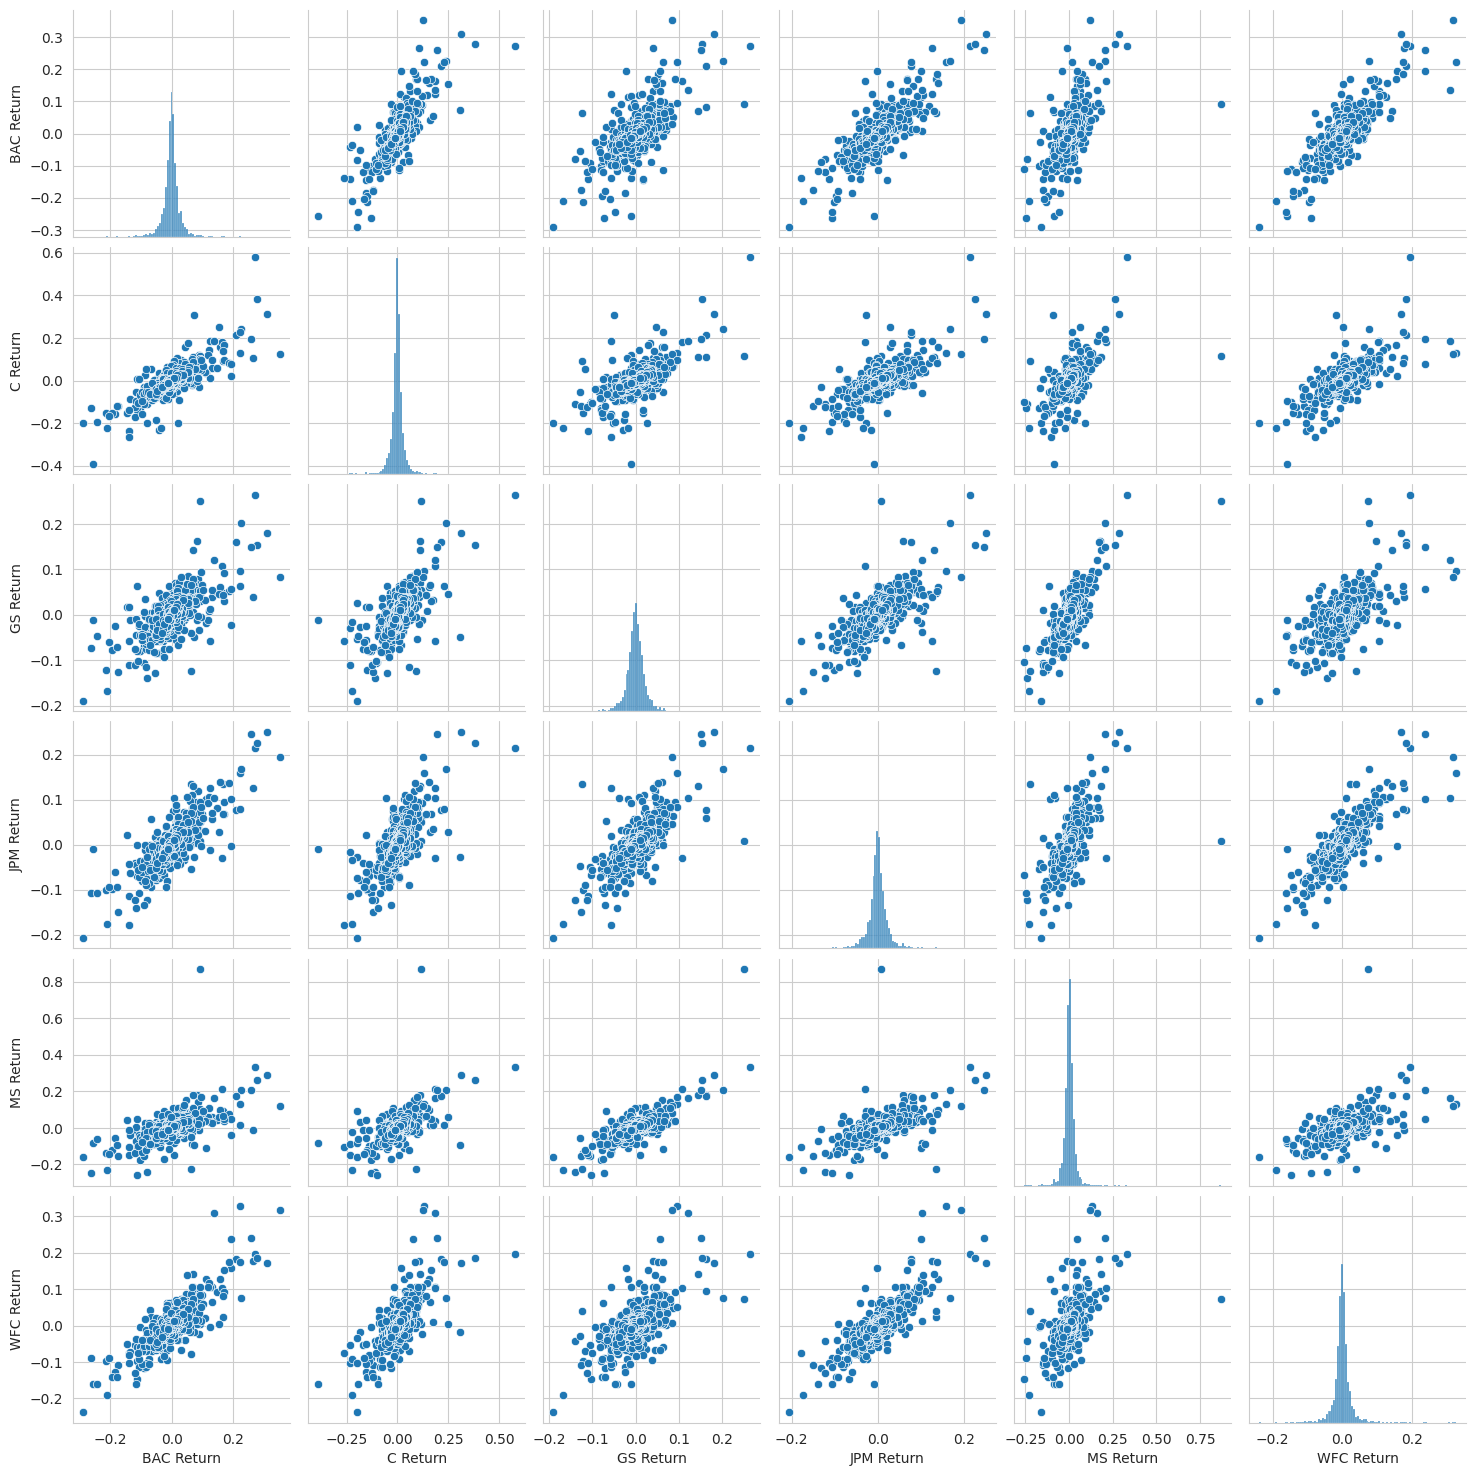

In [7]:
sns.pairplot(returns.dropna())
plt.show()

*À observer :* Citigroup a un nuage de points beaucoup plus étalé que les autres. Son cours s'est effondré en 2008-2009 (sauvetage par l'État américain), ce qui produit des rendements journaliers extrêmes.

**Meilleur et pire rendement journalier de chaque banque**

In [8]:
print("Pire journée (plus forte baisse) :")
print(returns.idxmin())
print()
print("Meilleure journée (plus forte hausse) :")
print(returns.idxmax())

Pire journée (plus forte baisse) :
BAC Return   2009-01-20
C Return     2009-02-27
GS Return    2009-01-20
JPM Return   2009-01-20
MS Return    2008-10-09
WFC Return   2009-01-20
dtype: datetime64[ns]

Meilleure journée (plus forte hausse) :
BAC Return   2009-04-09
C Return     2008-11-24
GS Return    2008-11-24
JPM Return   2009-01-21
MS Return    2008-10-13
WFC Return   2008-07-16
dtype: datetime64[ns]


*À observer :* plusieurs banques ont leur pire journée à la même date, autour de **janvier 2009** (investiture du président américain, craintes sur la nationalisation des banques). Pour Citigroup, les données non ajustées du projet d'origine montraient aussi un saut lié à son *reverse split* de mai 2011. Ici, Yahoo Finance fournit des cours déjà ajustés des splits : ce saut ne devrait donc pas apparaître.

**Quelle banque est la plus risquée ?** On compare l'écart-type des rendements (volatilité) sur toute la période, puis sur 2015.

In [9]:
print("Écart-type sur toute la période :")
print(returns.std().sort_values(ascending=False))
print()
print("Écart-type sur 2015 :")
print(returns.loc['2015-01-01':'2015-12-31'].std().sort_values(ascending=False))

Écart-type sur toute la période :
C Return      0.038672
MS Return     0.037819
BAC Return    0.036647
WFC Return    0.030238
JPM Return    0.027667
GS Return     0.025390
dtype: float64

Écart-type sur 2015 :
MS Return     0.016249
BAC Return    0.016163
C Return      0.015289
GS Return     0.014046
JPM Return    0.014017
WFC Return    0.012591
dtype: float64


*À observer :* sur toute la période, Citigroup est la plus volatile. Sur 2015, les profils de risque sont très proches entre les banques.

**Distribution des rendements de Morgan Stanley en 2015**

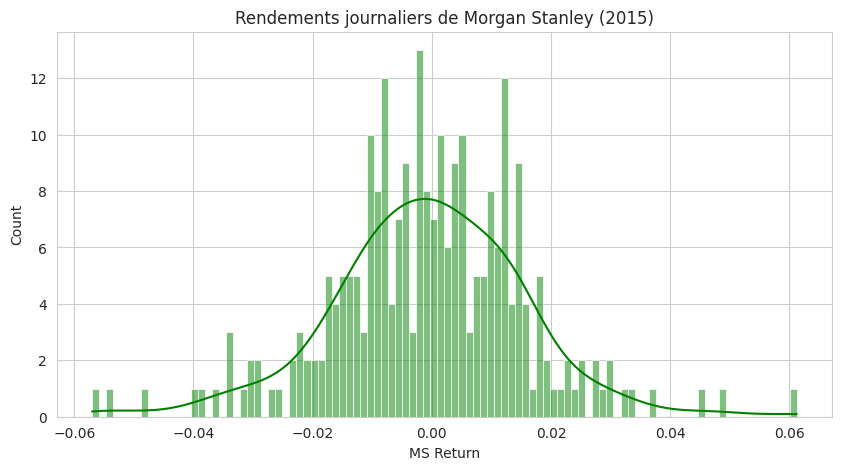

In [10]:
plt.figure(figsize=(10, 5))
sns.histplot(returns.loc['2015-01-01':'2015-12-31', 'MS Return'], bins=100, kde=True, color='green')
plt.title('Rendements journaliers de Morgan Stanley (2015)')
plt.show()

**Distribution des rendements de Citigroup en 2008**

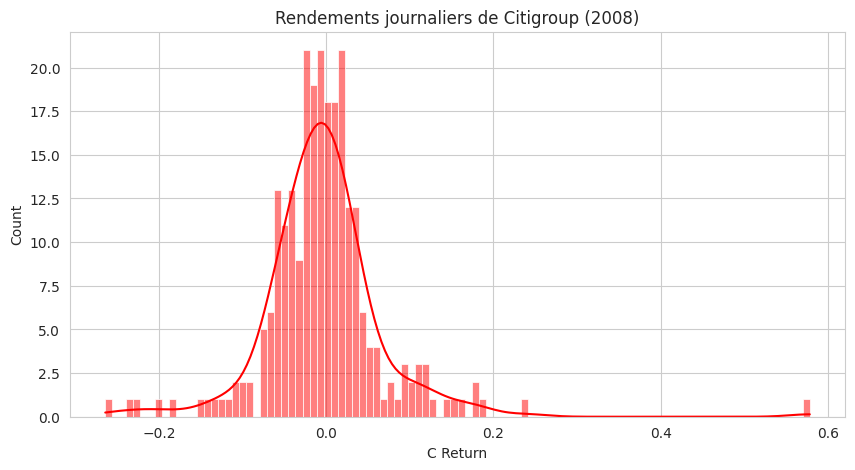

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(returns.loc['2008-01-01':'2008-12-31', 'C Return'], bins=100, kde=True, color='red')
plt.title('Rendements journaliers de Citigroup (2008)')
plt.show()

---
## 3. Visualisations

**Cours de clôture de chaque banque sur toute la période**

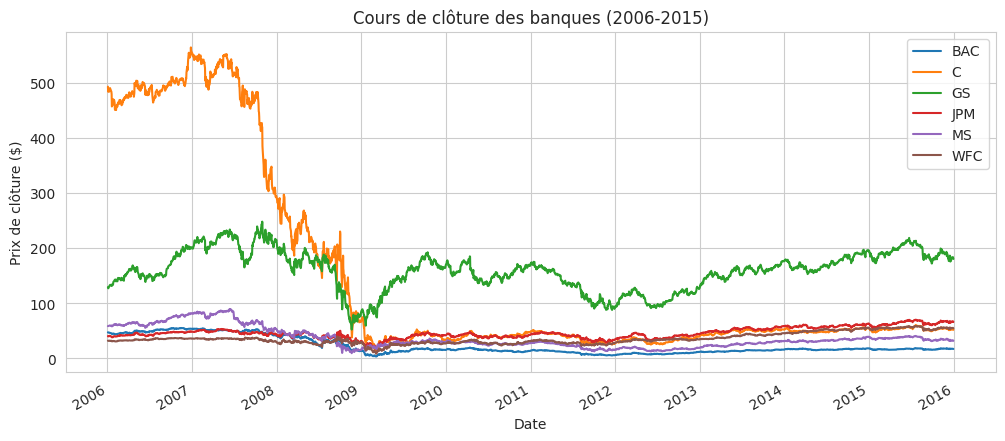

In [12]:
plt.figure(figsize=(12, 5))
for tick in tickers:
    bank_stocks[tick]['Close'].plot(label=tick)
plt.legend()
plt.title('Cours de clôture des banques (2006-2015)')
plt.ylabel('Prix de clôture ($)')
plt.show()

Même graphique en version interactive (Plotly) : tu peux zoomer et survoler les courbes.

In [13]:
fig = px.line(close, title='Cours de clôture des banques (interactif)')
fig.update_layout(xaxis_title='Date', yaxis_title='Prix de clôture ($)', legend_title='Banque')
fig.show()

### Moyennes mobiles

**Moyenne mobile sur 30 jours de Bank of America contre son cours de clôture, année 2008**

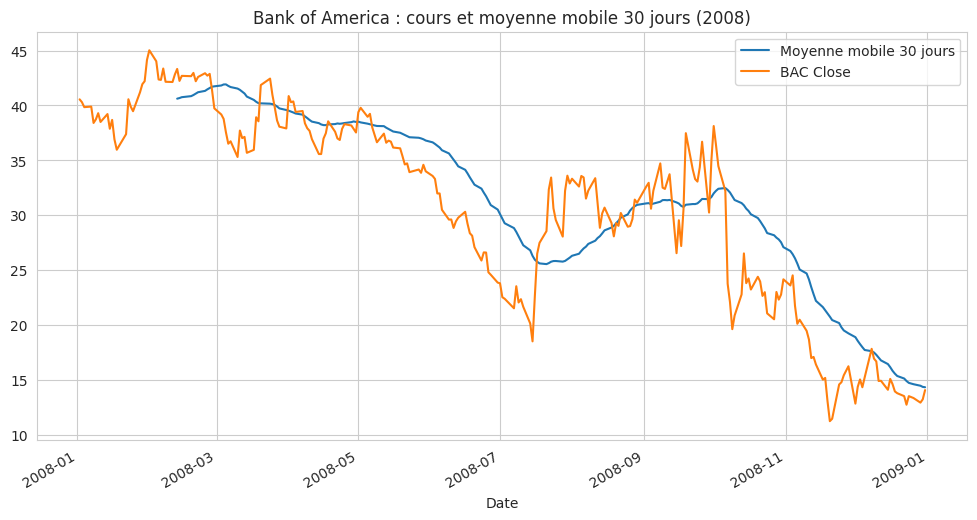

In [14]:
bac_2008 = BAC['Close'].loc['2008-01-01':'2009-01-01']

plt.figure(figsize=(12, 6))
bac_2008.rolling(window=30).mean().plot(label='Moyenne mobile 30 jours')
bac_2008.plot(label='BAC Close')
plt.legend()
plt.title('Bank of America : cours et moyenne mobile 30 jours (2008)')
plt.show()

**Corrélation entre les cours de clôture des banques**

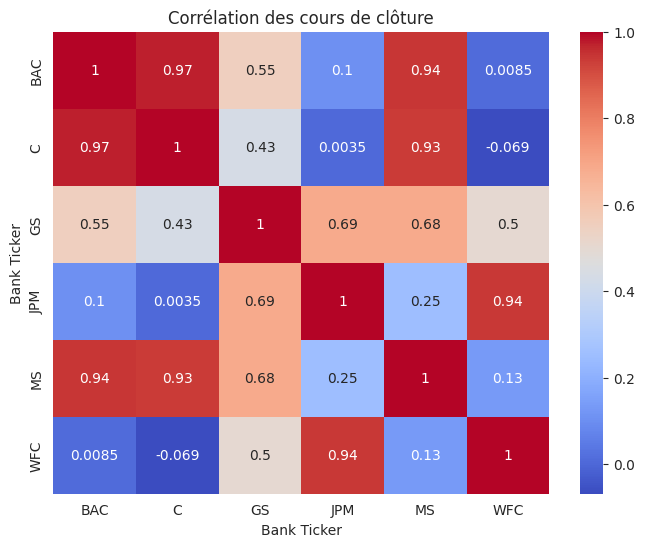

In [15]:
close_corr = close.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(close_corr, annot=True, cmap='coolwarm')
plt.title('Corrélation des cours de clôture')
plt.show()

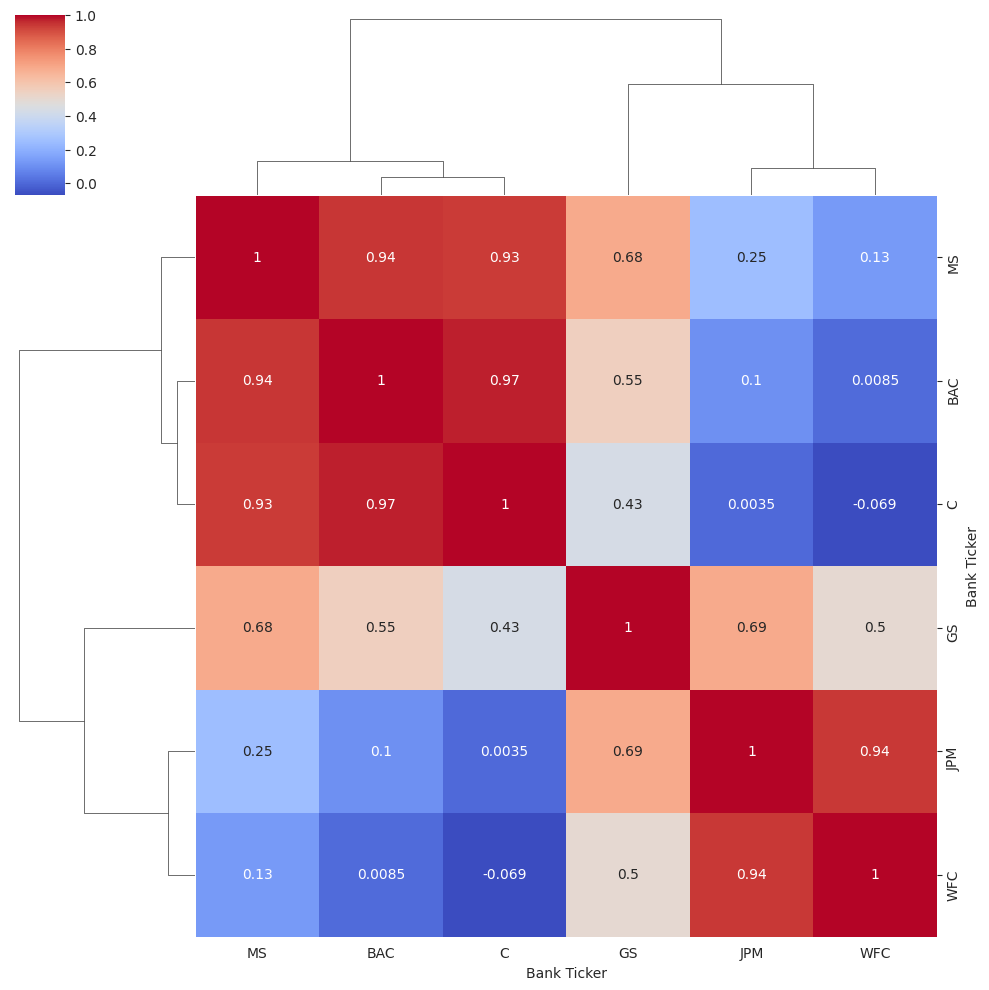

In [16]:
# Clustermap : regroupe les banques dont les cours sont les plus corrélés
sns.clustermap(close_corr, annot=True, cmap='coolwarm')
plt.show()

In [17]:
# Version interactive
fig = px.imshow(close_corr, text_auto='.2f', color_continuous_scale='RdYlBu',
                title='Corrélation des cours de clôture (interactif)')
fig.show()

---
## 4. Partie 2 : analyse technique (Plotly)

Le notebook d'origine utilisait `cufflinks`, qui ne fonctionne plus. On refait les mêmes graphiques avec Plotly.

**Graphique en chandeliers (candlestick) de Bank of America, du 1er janvier 2015 au 1er janvier 2016**

In [18]:
bac_2015 = BAC.loc['2015-01-01':'2016-01-01']

fig = go.Figure(data=[go.Candlestick(
    x=bac_2015.index,
    open=bac_2015['Open'], high=bac_2015['High'],
    low=bac_2015['Low'], close=bac_2015['Close'],
    name='BAC')])
fig.update_layout(title='Bank of America : chandeliers (2015)',
                  xaxis_rangeslider_visible=False,
                  yaxis_title='Prix ($)')
fig.show()

**Moyennes mobiles simples (SMA) de 13, 21 et 55 jours pour Morgan Stanley, année 2015**

In [19]:
ms_2015 = MS['Close'].loc['2015-01-01':'2016-01-01']

fig = go.Figure()
fig.add_trace(go.Scatter(x=ms_2015.index, y=ms_2015, name='MS Close', line=dict(color='gray')))
for p in [13, 21, 55]:
    fig.add_trace(go.Scatter(x=ms_2015.index, y=ms_2015.rolling(p).mean(), name=f'SMA {p}'))
fig.update_layout(title='Morgan Stanley : moyennes mobiles simples (2015)',
                  yaxis_title='Prix ($)')
fig.show()

**Bandes de Bollinger de Bank of America, année 2015**

Bandes = moyenne mobile 20 jours ± 2 écarts-types (20 jours).

In [20]:
bac_close = BAC['Close']
sma20 = bac_close.rolling(20).mean()
std20 = bac_close.rolling(20).std()
upper = sma20 + 2 * std20
lower = sma20 - 2 * std20

period = slice('2015-01-01', '2016-01-01')

fig = go.Figure()
fig.add_trace(go.Scatter(x=upper.loc[period].index, y=upper.loc[period],
                         name='Bande haute', line=dict(color='lightgray')))
fig.add_trace(go.Scatter(x=lower.loc[period].index, y=lower.loc[period],
                         name='Bande basse', line=dict(color='lightgray'),
                         fill='tonexty', fillcolor='rgba(200,200,200,0.3)'))
fig.add_trace(go.Scatter(x=sma20.loc[period].index, y=sma20.loc[period],
                         name='SMA 20', line=dict(color='orange')))
fig.add_trace(go.Scatter(x=bac_close.loc[period].index, y=bac_close.loc[period],
                         name='BAC Close', line=dict(color='blue')))
fig.update_layout(title='Bank of America : bandes de Bollinger (2015)',
                  yaxis_title='Prix ($)')
fig.show()

---
## 5. Conclusion

- Les 6 banques ont fortement chuté pendant la crise de 2008-2009, avec des cours très corrélés entre eux.
- **Citigroup** est la plus volatile de la période : son rendement journalier présente les valeurs les plus extrêmes.
- Les pires journées de plusieurs banques coïncident (début 2009), signe d'un risque **systémique** : le secteur bancaire a réagi comme un bloc.
- En 2015, les niveaux de risque des banques sont redevenus proches.
- Les moyennes mobiles et les bandes de Bollinger sont des outils d'analyse technique pour repérer les tendances et les périodes de forte volatilité.